# Spotify top-10s: exploration

![image.png](attachment:image.png)

![image.png](attachment:image.png)

# Analyse de données avec Python

# Spotify

Vous connaissez tous [spotify](https://www.spotify.com/fr/), un des plus
importants site d’écoute de musique. Je vous propose dans ce TD/TP
d’analyser et de visualiser des éléments du TOP50 de la musique (au
niveau mondial) des années 2010 à 2019.

Notre première approche avant de visualiser quoi que ce soit, sera bien
évidemment de nous familiariser avec ces données.

## Charger et se familiariser avec les données

La première étape est de charger les données, attention elles n’ont pas
été sauvegardées en UTF8 (malheureusement) mais au format ISO-8859-1.
Vous devez **passer ce codage** en option lors du chargement du fichier CSV.

-   Examinez les premières lignes du fichier
-   Donnez le nombre de lignes et de colonnes du fichier
-   En utilisant la méthode isnull() de pandas
    (<https://www.w3resource.com/pandas/isnull.php>). Analysez le
    fichier afin de rechercher les valeurs manquantes, vous pouvez
    également utiliser la méthode count()
-   En utilisant la méthode nunique()
    (<https://www.geeksforgeeks.org/python-pandas-series-nunique/>),
    analyser les données afin d’en extraire le nombre de chansons, le
    nombre d’artistes ainsi que le nombre de chansons. Vous pourrez
    ainsi constater que plusieurs artistes ont plusieurs chansons
    différentes dans ce top

J'ai trouvé sauf erreur de ma part qu'il y avait 184 artistes, 584
chansons et 50 genres différents

In [6]:
import pandas as pd
spotify = pd.read_csv('top10s.csv',encoding='ISO-8859-1')
spotify

,Unnamed: 0,title,artist,top genre,year,bpm,nrgy,dnce,dB,live,val,dur,acous,spch,pop
0,1,"Hey, Soul Sister",Train,neo mellow,2010,97,89,67,-4,8,80,217,19,4,83
1,2,Love The Way You Lie,Eminem,detroit hip hop,2010,87,93,75,-5,52,64,263,24,23,82
2,3,TiK ToK,Kesha,dance pop,2010,120,84,76,-3,29,71,200,10,14,80
3,4,Bad Romance,Lady Gaga,dance pop,2010,119,92,70,-4,8,71,295,0,4,79
4,5,Just the Way You Are,Bruno Mars,pop,2010,109,84,64,-5,9,43,221,2,4,78
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
598,599,Find U Again (feat. Camila Cabello),Mark Ronson,dance pop,2019,104,66,61,-7,20,16,176,1,3,75
599,600,Cross Me (feat. Chance the Rapper & PnB Rock),Ed Sheeran,pop,2019,95,79,75,-6,7,61,206,21,12,75
600,601,"No Brainer (feat. Justin Bieber, Chance the Ra...",DJ Khaled,dance pop,2019,136,76,53,-5,9,65,260,7,34,70
601,602,Nothing Breaks Like a Heart (feat. Miley Cyrus),Mark Ronson,dance pop,2019,114,79,60,-6,42,24,217,1,7,69


In [8]:
spotify.shape

(603, 15)

In [13]:
spotify.isnull()

,Unnamed: 0,title,artist,top genre,year,bpm,nrgy,dnce,dB,live,val,dur,acous,spch,pop
0,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
598,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
599,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
600,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
601,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False


In [24]:
spotify[["title","artist","top genre"]].nunique()

title        584
artist       184
top genre     50
dtype: int64

# Visualisation de plusieurs informations

## Artistes les plus écoutés

Je vous propose comme première visualisation de visualiser les 10
artistes les plus écoutés (en nombre de titres) dans ce top 50. La
méthode value_counts()
(<https://www.w3resource.com/pandas/series/series-value_counts.php>) qui
est une méthode extrêmement utilisée permet de compter le nombre
d’occurrences d’un même objet.

Affichez ces 10 artistes et en utilisant seaborn utiliser un « barplot »
pour les afficher.

Quel(le) est le/la chanteur(se) la plus écouté(e) ces 10 dernières
années, avec combien de titres ?

Pouvez-vous donner les titres les plus écoutés (*indice *: il y en a 17)

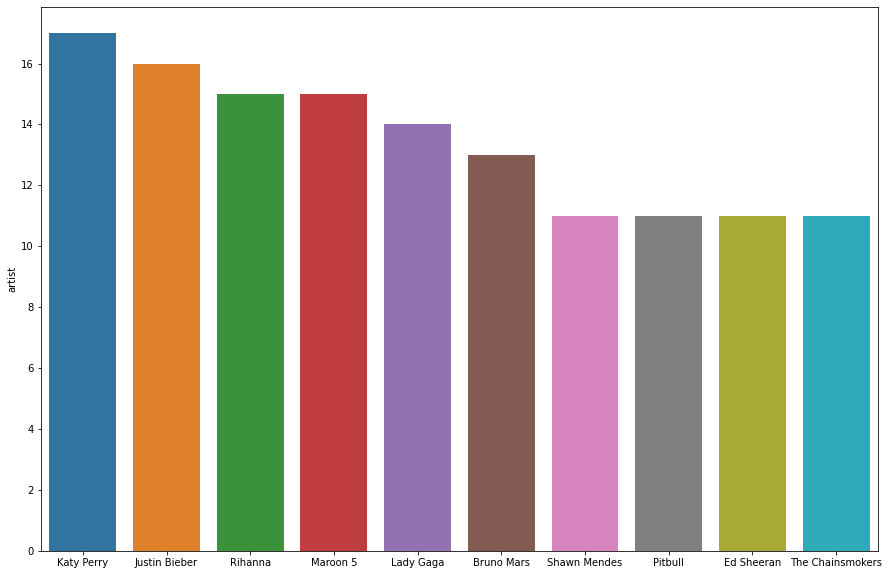

In [53]:
import seaborn as sbn
import matplotlib.pyplot as plt

top10=spotify["artist"].value_counts().head(10)
top10

fig = plt.figure(figsize=(15,10))
fig=sbn.barplot(x=top10.index,y=top10)

In [110]:
bestSinger=spotify["artist"].value_counts().head(1).index[0]
nb=spotify[spotify["artist"]== bestSinger].value_counts("title")
print("la meilleur chanteuse",bestSinger,"a fait",nb.value_counts().to_string(index=False),"chansons dans ces 10 derniers années :")
nb

la meilleur chanteuse Katy Perry a fait 17 chansons dans ces 10 derniers années :


title
Birthday                        1
Part Of Me                      1
This Is How We Do               1
The One That Got Away           1
Teenage Dream                   1
Swish Swish                     1
Roar                            1
Rise                            1
Legendary Lovers                1
Bon appétit                     1
Last Friday Night (T.G.I.F.)    1
Firework                        1
E.T.                            1
Dark Horse                      1
Chained To The Rhythm           1
California Gurls                1
Wide Awake                      1
dtype: int64

## Genres les plus populaires

Je vous propose dans le même ordre d'idée de visualiser les 10 genres
les plus populaires. Utiliser un « plot » et une graphique sous forme de
camemberts afin de visualiser les titres les plus populaires. Seaborn ne
propose pas de graphismes de type camembert mais matplotlib sait le
faire (<http://www.python-simple.com/python-matplotlib/pie.php>)

Vous devriez obtenir quelque chose qui ressemble à la figure
ci-dessous :

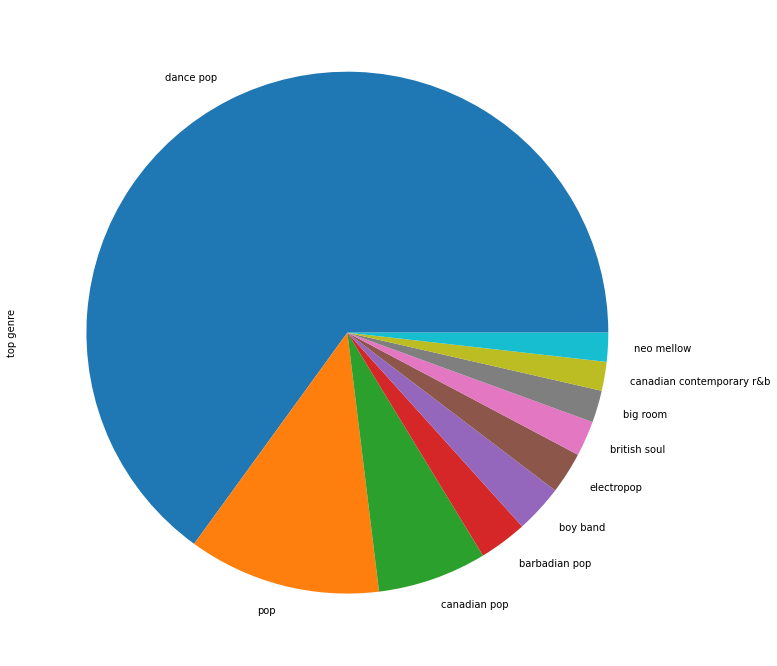

In [137]:
topGenre=spotify["top genre"].value_counts().head(10)
fig2 = plt.figure(figsize=(20,8))
fig2=topGenre.plot.pie(y=topGenre, figsize=(12, 12))

![image.png](attachment:image.png)

Les noms des genres sont volontairement absents mais si vous aimez la
musique « dance », vous n'êtes pas très très original !

## Durée des chansons

D'après les spécialistes de la musique, afin de survivre dans un monde
de plus en plus concurrentiel et des plus en plus pressé, les musiques
doivent être de plus en plus courtes sinon les auditeurs ne prennent
plus le temps de les écouter dans leur entièreté ! Il serait intéressant
de vérifier, si au cours de cette décade, la durée de la musique a
effectivement diminué en moyenne.

Extraire la durée des chansons sur la décennie

Vérifier on non ce fait avec un simple « lineplot ». Qu'en
déduisez-vous ?

Utilisez lmplot afin de cooroborer ce fait.

Il serait intéressant de vérifier cette durée en la comparant aux durées
moyennes des artistes du top10, en profiter pour extraire la chanson la
plus courte et la plus longue de chacun de ces artistes.

On peut transformer un index d'une Series ou DataFrame avec la commande
Python *tolist()*

Utilisez swarmplot pour obtenir le graphisme ci-dessous :
![image.png](attachment:image.png)

## BPM des chansons

Il est intéressant également de faire une analyse complémentaire en
analysant le [BPM](https://fr.wikipedia.org/wiki/Battement_par_minute)
moyen des morceaux ces dernières années. Utilisez lineplot pour
visualiser l'évolution des
[BPM](https://fr.wikipedia.org/wiki/Battement_par_minute) des années
2010 à 2019. Qu'en déduisez-vous ?

### Autre forme de visualisation

Une visualisation complémentaire de la durée (ou des BPM) de celle que
l'on a faite est la visualisation sous un histogramme afin de
représenter tous les morceaux et leur durée correspondante (voir le
tutoriel de seaborn à cette adresse
<https://seaborn.pydata.org/tutorial/distributions.html>)

![image.png](attachment:image.png)

Vous devriez obtenir un histogramme semblable à celui ci-dessus. Que
pouvez-vous en déduire ?

# Dépendance des variables

Nous abordons ici les limites du cours car nous ne faisons que de
l'analyse de données mais le cours d'explicabilité ou d'utilisation de
ML pour l’analyse de données (analyse par composantes principales,
régression des variables ou encore apprentissage automatique) sont des
notions que vous verrez en dernière année du cycle ingénieur, mais il
est possible assez facilement d'explorer quelques corrélations basiques
entre les variables.

Si on examine les données fournies par Spotify, on s'aperçoit qu'il y a
de nombreuses colonnes dont il pourrait être intéressant d'analyser les
corrélations.

top.columns

 Index(['Unnamed: 0', 'title', 'artist', 'top genre', 'year', 'bpm',
'nrgy', 'dnce', 'dB', 'live', 'val', 'dur', 'acous', 'spch', 'pop'],
dtype='object')

Je ne suis pas capable d'expliquer toutes les colonnes mais la colonne
dance correspond à la « dansabilité » du morceau. Nous pouvons étudier
la corrélation entre la dansabilité du morceau et le BPM.\*

Une droite de régression se dessine avec seaborn avec la commande
[regplot](https://seaborn.pydata.org/generated/seaborn.regplot.html?highlight=regplot#seaborn.regplot)
et en lui passant simplement les valeurs en x et en y

Étudiez la corrélation entre les BPM et la dansabilité des morceaux ?

Essayez de trouver les deux variables les plus corrélées